In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Video_Games_Sales_as_at_22_Dec_2016.csv to Video_Games_Sales_as_at_22_Dec_2016.csv


In [ ]:
df = pd.read_csv("Video_Games_Sales_as_at_22_Dec_2016.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.shape

(16719, 16)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  object 
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(9), object(7)
memory usage: 2.0+ MB


In [ ]:
print("File uploaded:")
print(uploaded.keys())

print("\nFirst 500 characters of the file:")
filename = list(uploaded.keys())[0]

with open(filename, "r", encoding="utf-8", errors="replace") as f:
    print(f.read(500))

File uploaded:
dict_keys(['Video_Games_Sales_as_at_22_Dec_2016.csv'])

First 500 characters of the file:
Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
Wii Sports,Wii,2006,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76,51,8,322,Nintendo,E
Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,,,,,,
Mario Kart Wii,Wii,2008,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82,73,8.3,709,Nintendo,E
Wii Sports Resort,Wii,2009,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80,73,8,


In [ ]:
df.describe()

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Count
count,16450.000000,16719.000000,16719.000000,16719.000000,16719.000000,16719.000000,8137.000000,8137.000000,7590.000000
mean,2006.487356,0.263330,0.145025,0.077602,0.047332,0.533543,68.967679,26.360821,162.229908
std,5.878995,0.813514,0.503283,0.308818,0.186710,1.547935,13.938165,18.980495,561.282326
min,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000,13.000000,3.000000,4.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000,60.000000,12.000000,10.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000,71.000000,21.000000,24.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,0.470000,79.000000,36.000000,81.000000
max,2020.000000,41.360000,28.960000,10.220000,10.570000,82.530000,98.000000,113.000000,10665.000000


Missing valaues

In [ ]:
missing = df.isnull().sum()

missing_percentage = (missing / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percentage
})

missing_summary.sort_values("Percentage", ascending=False)

,Missing Values,Percentage
User_Count,9129,54.602548
Critic_Count,8582,51.330821
Critic_Score,8582,51.330821
Rating,6769,40.486871
User_Score,6704,40.098092
Developer,6623,39.613613
Year_of_Release,269,1.608948
Publisher,54,0.322986
Name,2,0.011962
Genre,2,0.011962


Duplicate games

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


unique values

In [ ]:
print("Platforms:", df["Platform"].nunique())
print("Genres:", df["Genre"].nunique())
print("Publishers:", df["Publisher"].nunique())
print("Developers:", df["Developer"].nunique())
print("Ratings:", df["Rating"].nunique())

Platforms: 31
Genres: 12
Publishers: 581
Developers: 1696
Ratings: 8


Gmes by genre

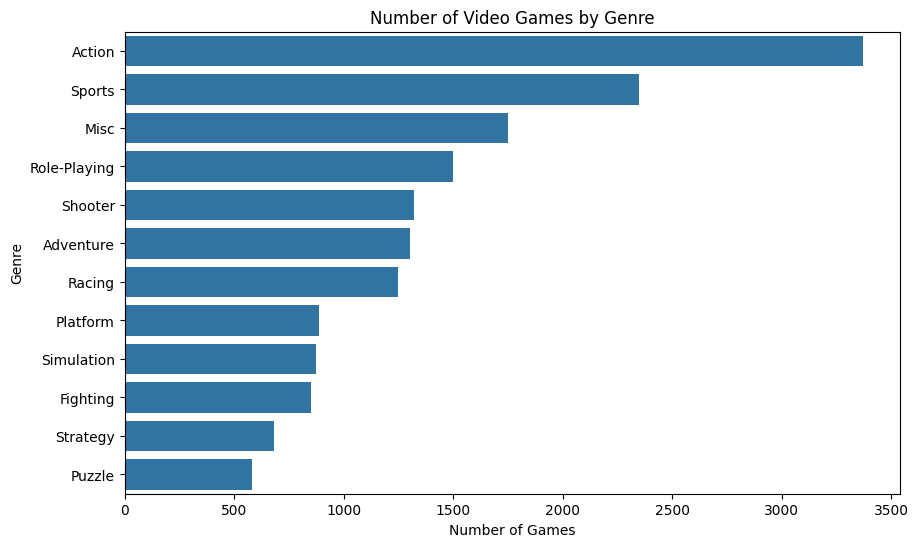

In [ ]:
genre_counts = df["Genre"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Video Games by Genre")
plt.xlabel("Number of Games")
plt.ylabel("Genre")
plt.show()

Global sales by genre

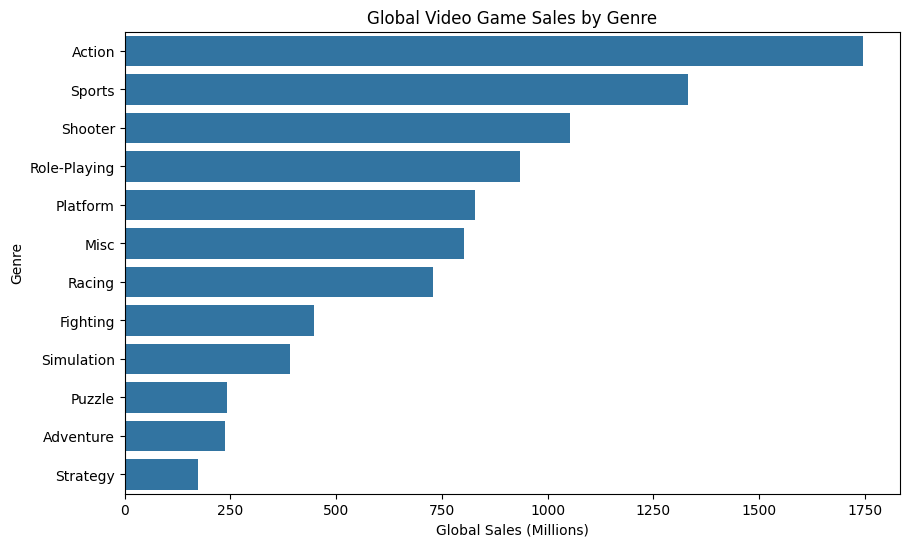

In [ ]:
genre_sales = (
    df.groupby("Genre")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=genre_sales.values,
    y=genre_sales.index
)

plt.title("Global Video Game Sales by Genre")
plt.xlabel("Global Sales (Millions)")
plt.ylabel("Genre")
plt.show()

Platform sales

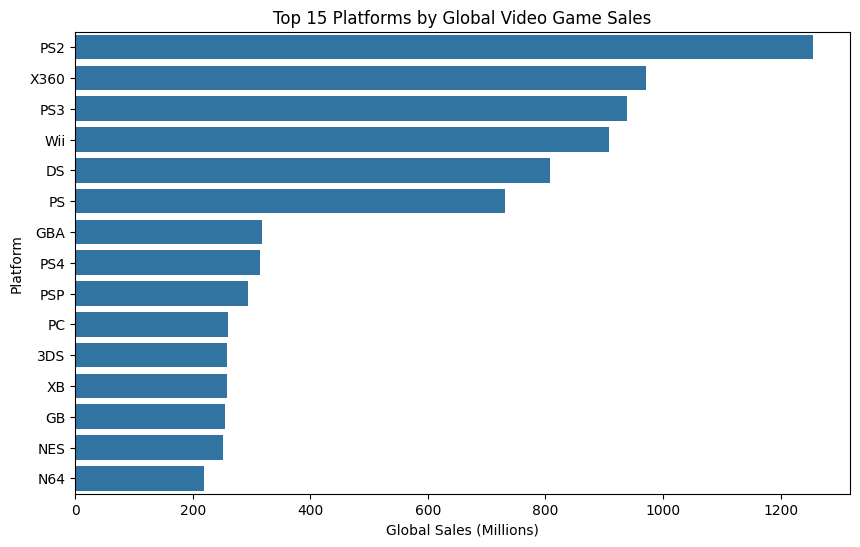

In [ ]:
platform_sales = (
    df.groupby("Platform")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=platform_sales.values,
    y=platform_sales.index
)

plt.title("Top 15 Platforms by Global Video Game Sales")
plt.xlabel("Global Sales (Millions)")
plt.ylabel("Platform")
plt.show()

Games released over time

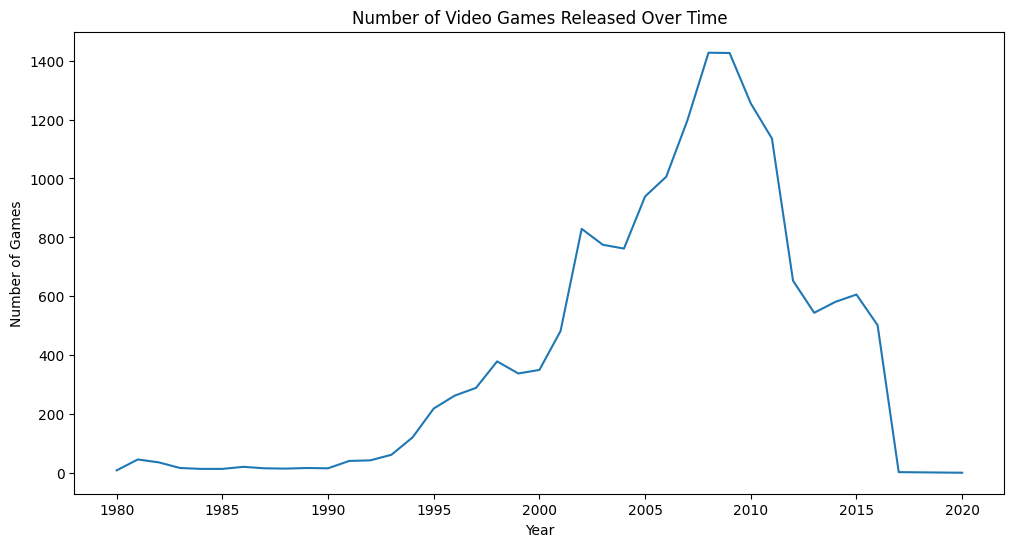

In [ ]:
games_by_year = df["Year_of_Release"].value_counts().sort_index()

plt.figure(figsize=(12, 6))
plt.plot(games_by_year.index, games_by_year.values)

plt.title("Number of Video Games Released Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Games")
plt.show()

User Score

In [ ]:
df["User_Score"] = pd.to_numeric(df["User_Score"], errors="coerce")

print(df["User_Score"].dtype)

float64


Correlation matrix

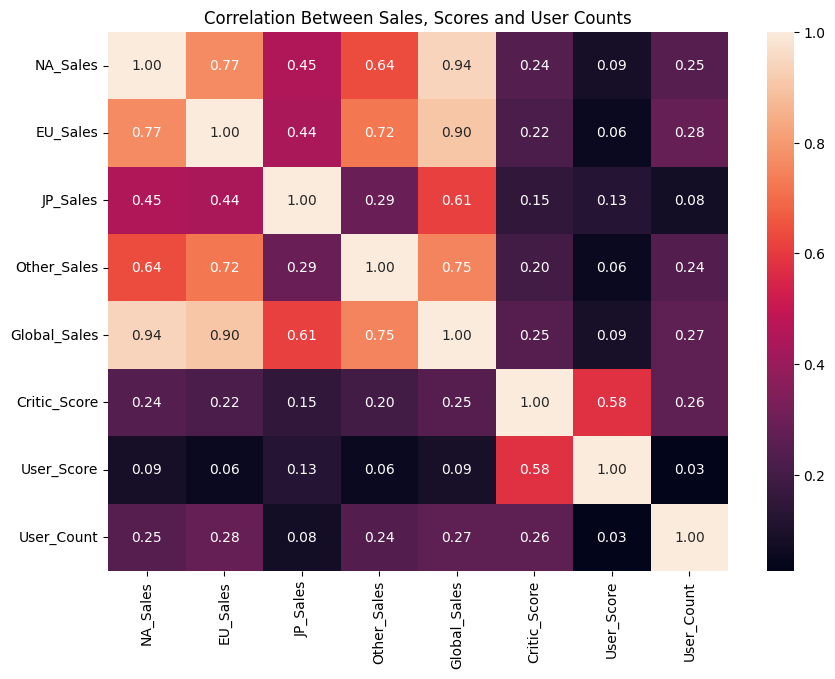

In [ ]:
correlation_data = df[
    ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales",
     "Global_Sales", "Critic_Score", "User_Score", "User_Count"]
]

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Sales, Scores and User Counts")
plt.show()

Critic Score vs Global Sales

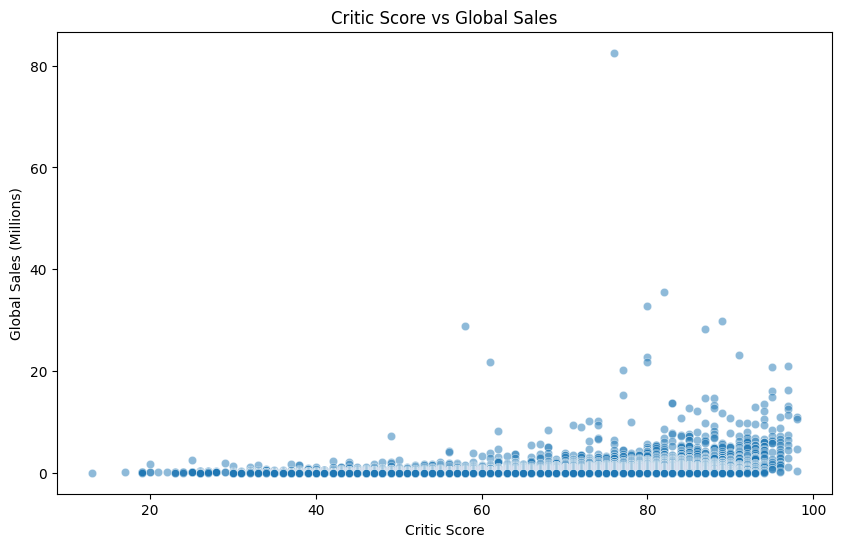

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Critic_Score",
    y="Global_Sales",
    alpha=0.5
)

plt.title("Critic Score vs Global Sales")
plt.xlabel("Critic Score")
plt.ylabel("Global Sales (Millions)")
plt.show()

User Score vs Global Sales

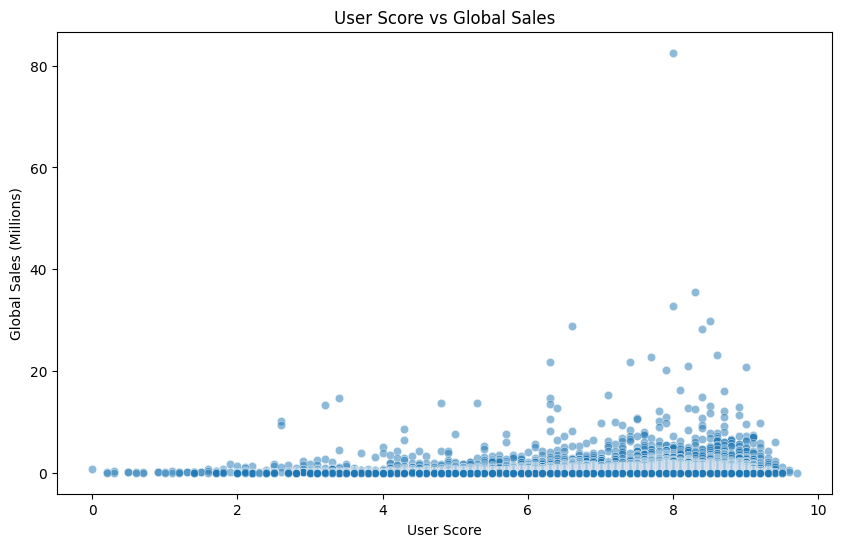

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="User_Score",
    y="Global_Sales",
    alpha=0.5
)

plt.title("User Score vs Global Sales")
plt.xlabel("User Score")
plt.ylabel("Global Sales (Millions)")
plt.show()

**ML**

success threshold

In [ ]:
sales_threshold = df["Global_Sales"].quantile(0.75)

print("75th percentile sales threshold:", sales_threshold)

75th percentile sales threshold: 0.47


The target variable

In [ ]:
df["High_Sales"] = (
    df["Global_Sales"] >= sales_threshold
).astype(int)

print(df["High_Sales"].value_counts())

High_Sales
0    12513
1     4206
Name: count, dtype: int64


ML DATASET

In [ ]:
ml_df = df[
    [
        "Platform",
        "Year_of_Release",
        "Genre",
        "Publisher",
        "Critic_Score",
        "Critic_Count",
        "User_Score",
        "User_Count",
        "Developer",
        "Rating",
        "High_Sales"
    ]
].copy()

print("Original ML dataset shape:", ml_df.shape)

Original ML dataset shape: (16719, 11)


Handling th emmissig values

In [ ]:
numeric_columns = [
    "Year_of_Release",
    "Critic_Score",
    "Critic_Count",
    "User_Score",
    "User_Count"
]

categorical_columns = [
    "Platform",
    "Genre",
    "Publisher",
    "Developer",
    "Rating"
]

for column in numeric_columns:
    ml_df[column] = ml_df[column].fillna(
        ml_df[column].median()
    )

for column in categorical_columns:
    ml_df[column] = ml_df[column].fillna("Unknown")

print("Remaining missing values:")
print(ml_df.isnull().sum())

Remaining missing values:
Platform           0
Year_of_Release    0
Genre              0
Publisher          0
Critic_Score       0
Critic_Count       0
User_Score         0
User_Count         0
Developer          0
Rating             0
High_Sales         0
dtype: int64


converting categories to numbers using one hot encoding

In [ ]:
X = ml_df.drop("High_Sales", axis=1)
y = ml_df["High_Sales"]

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
)

print("Features:", X.shape)

Features: (16719, 2331)


Training

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 13375
Testing samples: 3344


Decision tree

In [ ]:
decision_tree = DecisionTreeClassifier(
    max_depth=8,
    random_state=42
)

decision_tree.fit(X_train, y_train)

dt_predictions = decision_tree.predict(X_test)

dt_accuracy = accuracy_score(
    y_test,
    dt_predictions
)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.8184808612440191


Random Forest

In [ ]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7559808612440191


Model comparision

In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy
    ]
})

model_comparison

,Model,Accuracy
0,Decision Tree,0.818481
1,Random Forest,0.755981


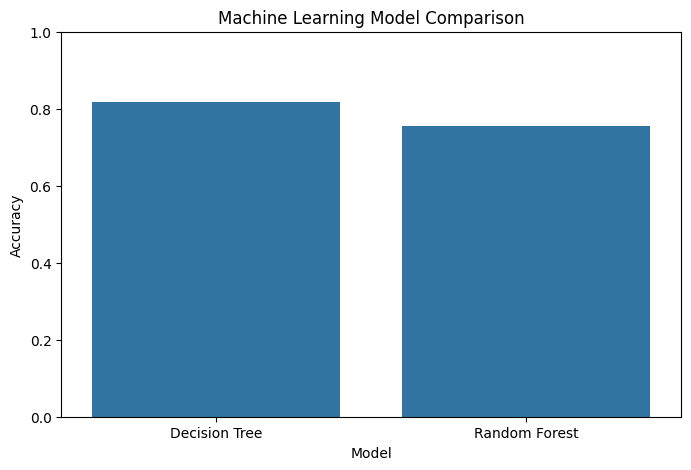

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)
plt.title("Machine Learning Model Comparison")
plt.ylabel("Accuracy")
plt.show()

decision tree evaluation

In [ ]:
print("Decision Tree Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        dt_predictions,
        target_names=["Low Sales", "High Sales"]
    )
)

Decision Tree Classification Report
------------------------------------
              precision    recall  f1-score   support

   Low Sales       0.84      0.94      0.89      2503
  High Sales       0.72      0.46      0.56       841

    accuracy                           0.82      3344
   macro avg       0.78      0.70      0.72      3344
weighted avg       0.81      0.82      0.80      3344



Random Forest evaluation

In [ ]:
print("Random Forest Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Low Sales", "High Sales"]
    )
)

Random Forest Classification Report
------------------------------------
              precision    recall  f1-score   support

   Low Sales       0.75      1.00      0.86      2503
  High Sales       1.00      0.03      0.06       841

    accuracy                           0.76      3344
   macro avg       0.88      0.51      0.46      3344
weighted avg       0.82      0.76      0.66      3344



confusion matrix

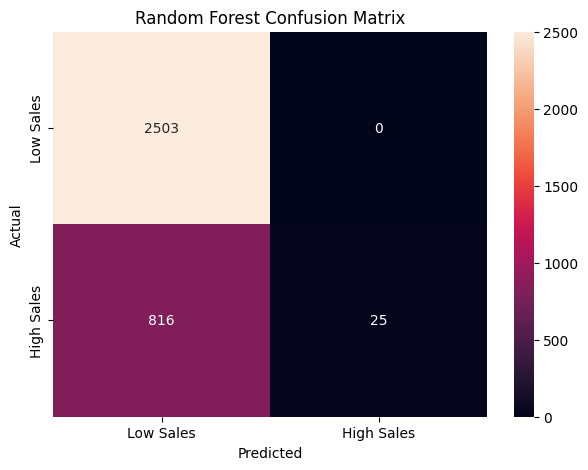

In [ ]:
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Low Sales", "High Sales"],
    yticklabels=["Low Sales", "High Sales"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Feature importance

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
4,User_Count,0.137397
2,Critic_Count,0.101265
1,Critic_Score,0.096427
3,User_Score,0.064804
185,Publisher_Electronic Arts,0.050886
407,Publisher_Nintendo,0.044404
0,Year_of_Release,0.043993
35,Genre_Adventure,0.023552
15,Platform_NES,0.021847
2330,Rating_Unknown,0.018635


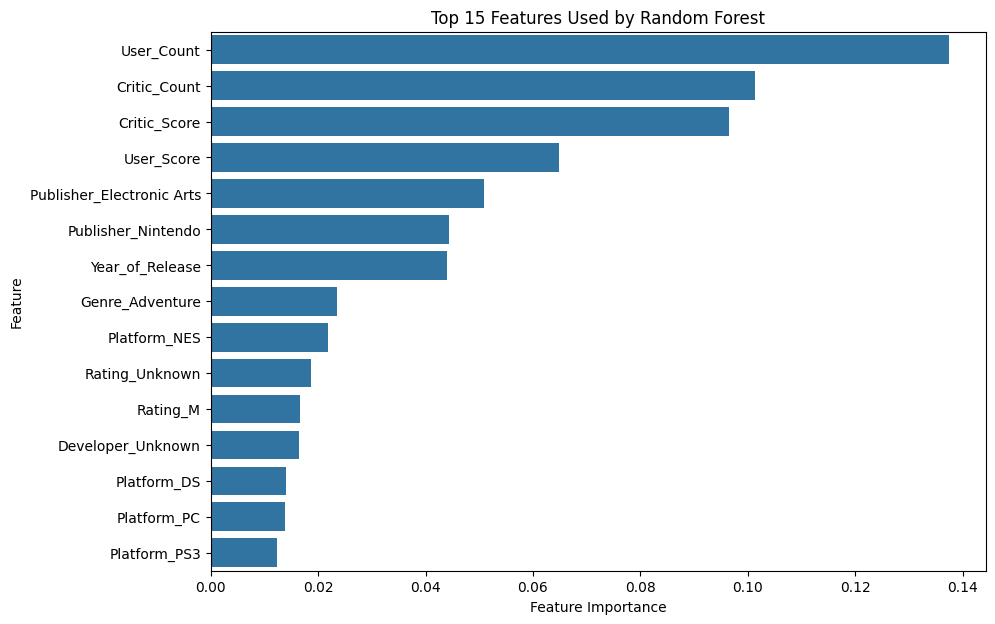

In [ ]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Used by Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

Example prediction

In [ ]:
example_game = X_test.iloc[[0]]

prediction = random_forest.predict(example_game)[0]

if prediction == 1:
    print("🎮 Prediction: HIGH SALES")
else:
    print("🎮 Prediction: LOW SALES")

🎮 Prediction: LOW SALES
